# INF201 Deliverable 2: Campus Coffee Shop Sales Pipeline

**Group:** Theodor Furuseth and Didrik Wang Berthinsen

**Github** https://github.com/Didrikwang/Campus_coffee_shop

This notebook builds a data pipeline for the Campus Coffee Shop Chain. It discovers all cash register
log files in a nested folder structure, reads them regardless of character encoding, parses valid
sales lines with regular expressions, cleans price glitches with NumPy, corrects NOK prices, and
produces summary reports with Pandas.

**Before running:** the input data is generated in the first cell of Task 5, which contains the
code from `generate_data_for_d2.py` with `BASE_DIR` set to `Path("data")`.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
CONFIG_FILE = DATA_DIR / "store_config.json"
OUTPUT_DIR = Path("output")

STATUSES = ["SUCCESS", "REFUND", "CANCELLED"]

## Task 1: File ingestion and regular expressions

### 1.1 Robust file reader

Plain text files carry no reliable metadata about their encoding. Following the method from
lecture 5, we first try to decode the raw bytes as UTF-8. UTF-8 has strict rules for multi-byte
sequences, so a Latin-1 file containing characters such as `é` (byte `0xE9`) will almost always
raise a `UnicodeDecodeError`. When that happens we fall back to ISO-8859-1 (Latin-1), which can decode
any byte sequence and therefore never fails.

The order matters: trying Latin-1 first would "succeed" on UTF-8 files too, but turn `é` into `Ã©`.

In [2]:
def read_log_file(file_path: Path) -> tuple:
    """Read a file encoded in UTF-8 or ISO-8859-1 and return (text, encoding_used)."""
    raw_bytes = Path(file_path).read_bytes()

    try:
        return raw_bytes.decode("utf-8"), "utf-8"
    except UnicodeDecodeError:
        return raw_bytes.decode("iso-8859-1"), "iso-8859-1"

### 1.2 Log parser with regular expressions

A valid line looks like this:

```
[2026-10-15 08:30:00] [POS_01] item=Latte price=4.50 EUR (SUCCESS)
```

We use named groups (`(?P<name>...)`) so each captured field can be read by name. Design choices:

- `item=(?P<item>.+?)\s+price=` uses a non-greedy match, so item names with spaces or non-ASCII
  characters (for example `Café au Lait`) are captured in full.
- `price` matches numbers with decimals, such as `4.50`.
- `status` only accepts the three legal values, so corrupted lines are rejected.
- `^` and `$` anchor the pattern to the whole line. Noise lines such as
  `--- PRINTER PAPER LOW WARNING ---` do not match and are skipped.

In [3]:
LOG_LINE_PATTERN = re.compile(
    r"^\[(?P<timestamp>\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\]\s+"
    r"\[(?P<register_id>\w+)\]\s+"
    r"item=(?P<item>.+?)\s+"
    r"price=(?P<price>\d+\.\d+)\s+"
    r"(?P<currency>[A-Z]{3})\s+"
    r"\((?P<status>SUCCESS|REFUND|CANCELLED)\)\s*$"
)


def parse_log_text(text: str) -> list[dict]:
    """Return a list of dictionaries, one for each valid sales line in the text."""
    records = []
    for line in text.splitlines():
        match = LOG_LINE_PATTERN.match(line.strip())
        if match is None:
            continue
        record = match.groupdict()
        record["price"] = float(record["price"])
        records.append(record)
    return records

In [4]:
example_text = """[2026-10-15 08:30:00] [POS_01] item=Latte price=4.50 EUR (SUCCESS)
--- PRINTER PAPER LOW WARNING ---
[2026-10-15 08:31:12] [POS_01] item=Café au Lait price=40.00 NOK (REFUND)
=== NETWORK SYNC OK ===
[2026-10-15 08:32:00] [POS_01] item=Latte price=4.50 EUR (UNKNOWN)"""

parse_log_text(example_text)

[{'timestamp': '2026-10-15 08:30:00',
  'register_id': 'POS_01',
  'item': 'Latte',
  'price': 4.5,
  'currency': 'EUR',
  'status': 'SUCCESS'},
 {'timestamp': '2026-10-15 08:31:12',
  'register_id': 'POS_01',
  'item': 'Café au Lait',
  'price': 40.0,
  'currency': 'NOK',
  'status': 'REFUND'}]

The two noise lines and the line with an invalid status are skipped. The item name with a space
and an accented character is captured correctly.

## Task 2: Recursive utility functions

### 2.1 Recursive directory search

The function follows the structure from lecture 5: a **base case** (a file, which is either added or
ignored) and a **recursive step** (a directory, which we search by calling the function again).
`Path.glob()`, `Path.rglob()` and `os.walk()` are not used. The result is sorted so the
output is the same on every operating system.

In [5]:
def find_log_files(directory: Path, extension: str = ".log") -> list:
    """Recursively find all files with the given extension and return them as Path objects."""
    directory = Path(directory)
    found_files = []

    for item in directory.iterdir():
        if item.is_dir():
            # Recursive step: search the subdirectory
            found_files.extend(find_log_files(item, extension))
        elif item.is_file() and item.suffix == extension:
            # Base case: a matching file
            found_files.append(item)

    return sorted(found_files)

### 2.2 Recursive search for active registers

The config file can nest dictionaries and lists in any combination, so we cannot rely on a fixed
path such as `regions -> stores -> registers`. Instead the function inspects the type of each node:

- **dict:** if it has an `id` and `"active": true`, the id is collected. Then every value is searched.
- **list:** every element is searched.
- **anything else** (string, number, bool): base case, nothing to collect.

In [6]:
def find_active_register_ids(node) -> set[str]:
    """Recursively collect the ids of all registers where "active" is true."""
    active_ids = set()

    if isinstance(node, dict):
        if "id" in node and node.get("active"):
            active_ids.add(node["id"])
        for value in node.values():
            active_ids.update(find_active_register_ids(value))

    elif isinstance(node, list):
        for element in node:
            active_ids.update(find_active_register_ids(element))

    # Base case: strings, numbers and booleans contain no registers
    return active_ids


def load_store_config(config_path: Path) -> dict:
    """Load the store config JSON file."""
    with open(config_path, encoding="utf-8") as file:
        return json.load(file)

In [7]:
example_config = {
    "company": "Campus Coffee",
    "regions": [{
        "region_name": "Main Campus",
        "stores": [{
            "name": "Library Cafe",
            "registers": [{"id": "POS_01", "active": True},
                          {"id": "POS_02", "active": False}],
        }],
    }],
}
find_active_register_ids(example_config)

{'POS_01'}

## Task 3: Functions for cleaning and analysing data using NumPy

### 3.1 Removing price outliers

A value $x$ is an outlier if $|x - \mu| > 3\sigma$, where $\mu$ is the mean and $\sigma$ the
standard deviation of all prices. Outliers are replaced by the median of the **valid** prices
(the non-outliers), so the glitches themselves do not influence the replacement value.

The comparison gives an array of True/False values (one per price). We use it to pick out the
outliers and replace them. We work on a copy so the input array is not changed.

In [8]:
def remove_price_outliers(prices, n_std: float = 3.0) -> np.ndarray:
    """Replace prices more than n_std standard deviations from the mean with the valid median."""
    price_array = np.array(prices, dtype=float)

    mean = price_array.mean()
    std = price_array.std()
    is_outlier = np.abs(price_array - mean) > n_std * std

    cleaned = price_array.copy()
    cleaned[is_outlier] = np.median(price_array[~is_outlier])
    return cleaned

In [9]:
test_prices = np.array([4.5, 3.0, 4.2, 5.5, 3.1, 4.0, 4.8, 3.9, 4.4, 5.0,
                        4.1, 3.6, 4.7, 5.2, 3.3, 4.6, 4.3, 3.8, 5.1, 999.0])
remove_price_outliers(test_prices)

array([4.5, 3. , 4.2, 5.5, 3.1, 4. , 4.8, 3.9, 4.4, 5. , 4.1, 3.6, 4.7,
       5.2, 3.3, 4.6, 4.3, 3.8, 5.1, 4.3])

### 3.2 Refund ratio

$$\text{Refund Ratio} = \frac{\text{Refund Count}}{\text{Sales Count} + \epsilon}, \qquad \epsilon = 10^{-6}$$

Adding $\epsilon$ prevents division by zero for items with no successful sales.

In [10]:
EPSILON = 1e-6


def compute_refund_ratio(sales_count: np.ndarray, refund_count: np.ndarray) -> np.ndarray:
    """Compute the refund ratio element-wise: refund_count / (sales_count + epsilon)."""
    return refund_count / (sales_count + EPSILON)


compute_refund_ratio(np.array([10, 4, 0]), np.array([1, 2, 0]))

array([0.09999999, 0.49999988, 0.        ])

## Task 4: Data analysis using Pandas

### 4.1 Building the DataFrame

In [11]:
def build_transaction_dataframe(records: list[dict]) -> pd.DataFrame:
    """Convert the records to a DataFrame with timestamp as a sorted datetime index."""
    df = pd.DataFrame(records)
    df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y-%m-%d %H:%M:%S")
    df = df.set_index("timestamp").sort_index()
    return df

### 4.2 Hourly revenue per item

`groupby("item")` followed by `resample("1h")` creates one time series per item with one-hour bins.
This requires the DatetimeIndex from 4.1. Hours without sales get the value 0.

In [12]:
def hourly_revenue_per_item(df: pd.DataFrame) -> pd.Series:
    """Return the total price per item for each one-hour window."""
    return df.groupby("item")["price"].resample("1h").sum()

### 4.3 Pivot table: revenue by item and status

Selecting `pivot[STATUSES]` puts the columns in a fixed order: SUCCESS, REFUND, CANCELLED.

In [13]:
def status_pivot_table(df: pd.DataFrame) -> pd.DataFrame:
    """Pivot table with total price per item (rows) and status (columns)."""
    pivot = pd.pivot_table(df, values="price", index="item", columns="status",
                           aggfunc="sum", fill_value=0)
    return pivot[STATUSES]

### 4.4 Refund ratio per item

We use the same pivot table approach as in 4.3, but with `aggfunc="count"` to count transactions
instead of summing prices. The `SUCCESS` and `REFUND` columns are then passed as NumPy arrays to
`compute_refund_ratio` from Task 3. Sales count is interpreted as the number of
successful transactions.

In [14]:
def refund_ratio_per_item(df: pd.DataFrame) -> pd.DataFrame:
    """Count sales and refunds per item and compute the refund ratio."""
    counts = pd.pivot_table(df, values="price", index="item", columns="status",
                            aggfunc="count", fill_value=0)

    sales = counts["SUCCESS"].to_numpy()
    refunds = counts["REFUND"].to_numpy()

    result = pd.DataFrame(index=counts.index)
    result["sales_count"] = sales
    result["refund_count"] = refunds
    result["refund_ratio"] = compute_refund_ratio(sales, refunds)
    return result

## Task 5: Full workflow

The workflow follows the steps in the assignment. Two design decisions:

- **Active registers:** after building the DataFrame we keep only transactions from registers that
  are active in the config. This is done *before* outlier cleaning, so data from inactive registers
  does not affect the mean and standard deviation.
- **Order of cleaning:** outlier cleaning runs *before* the NOK correction, as specified. Before the
  correction all prices are on a similar scale (about 3-6), so the 999.00 glitches stand out clearly.
  Multiplying NOK first would create two price clusters and inflate the standard deviation.

In [15]:
NOK_CORRECTION_FACTOR = 10.0


def save_hourly_revenue_json(hourly: pd.Series, output_path: Path) -> None:
    """Save hourly revenue as {item: {timestamp: revenue}} in a JSON file."""
    report = {}
    for (item, timestamp), revenue in hourly.items():
        if item not in report:
            report[item] = {}
        report[item][str(timestamp)] = round(float(revenue), 2)

    with open(output_path, "w", encoding="utf-8") as file:
        json.dump(report, file, indent=2)


def run_pipeline(data_dir: Path, config_file: Path, output_dir: Path) -> dict:
    """Run the full pipeline, save the output files and return the results in a dictionary."""
    # Step 1: find log files and active registers
    log_files = find_log_files(data_dir)
    active_ids = find_active_register_ids(load_store_config(config_file))

    # Step 2: read and parse every log file
    records = []
    encodings_used = {}
    for log_file in log_files:
        text, encoding = read_log_file(log_file)
        encodings_used[encoding] = encodings_used.get(encoding, 0) + 1
        records.extend(parse_log_text(text))

    # Step 3: build the DataFrame and keep only active registers
    df_raw = build_transaction_dataframe(records)
    df = df_raw[df_raw["register_id"].isin(active_ids)].copy()

    # Step 4: NumPy outlier cleaning
    raw_prices = df["price"].to_numpy()
    cleaned_prices = remove_price_outliers(raw_prices)
    n_outliers = int(np.sum(cleaned_prices != raw_prices))
    df["price"] = cleaned_prices

    # Step 5: currency correction, NOK prices are multiplied by 10
    is_nok = df["currency"] == "NOK"
    df.loc[is_nok, "price"] = df.loc[is_nok, "price"] * NOK_CORRECTION_FACTOR

    # Step 6: reports
    hourly = hourly_revenue_per_item(df)
    pivot = status_pivot_table(df)
    refund_ratios = refund_ratio_per_item(df)

    # Step 7: save outputs
    output_dir.mkdir(parents=True, exist_ok=True)
    df.to_csv(output_dir / "cleaned_transactions.csv")
    save_hourly_revenue_json(hourly, output_dir / "hourly_revenue.json")
    pivot.round(2).to_csv(output_dir / "status_pivot_table.csv")
    refund_ratios.to_csv(output_dir / "item_refund_ratios.csv")

    return {
        "log_files": log_files,
        "active_ids": active_ids,
        "encodings_used": encodings_used,
        "df_raw": df_raw,
        "raw_prices": raw_prices,
        "df": df,
        "cleaned_prices": cleaned_prices,
        "n_outliers": n_outliers,
        "hourly": hourly,
        "pivot": pivot,
        "refund_ratios": refund_ratios,
    }

In [16]:
import random
from datetime import datetime, timedelta


GEN_DIR = Path("data")
STORES = ["library_cafe", "science_building", "student_union"]
REGISTERS = ["POS_01", "POS_02", "POS_03"]
ITEMS = [("Espresso", 3.00), ("Latte", 4.50), ("Cappuccino", 4.20),
         ("Muffin", 3.50), ("Croissant", 3.80), ("Sandwich", 7.50)]
GEN_STATUSES = ["SUCCESS", "SUCCESS", "SUCCESS", "SUCCESS", "REFUND", "CANCELLED"]
NOISE_LINES = ["--- PRINTER PAPER LOW ---", "[DEBUG] BARCODE SCANNER REBOOTED",
               "=== NETWORK SYNC OK ==="]

file_idx = 0
for store in STORES:
    for reg in REGISTERS:
        folder = GEN_DIR / "2026" / store / reg
        folder.mkdir(parents=True, exist_ok=True)
        encoding = "utf-8" if file_idx % 2 == 0 else "iso-8859-1"
        lines = []
        current_time = datetime(2026, 10, 15, 7, 0, 0)
        for _ in range(80):
            current_time += timedelta(seconds=random.randint(10, 180))
            if random.random() < 0.15:
                lines.append(random.choice(NOISE_LINES) + "\n")
            item_name, base_price = random.choice(ITEMS)
            price = 999.00 if random.random() < 0.03 else round(base_price + random.uniform(-0.5, 0.5), 2)
            lines.append(f"[{current_time:%Y-%m-%d %H:%M:%S}] [{reg}] item={item_name} "
                         f"price={price:.2f} {random.choice(['EUR', 'NOK', 'USD'])} "
                         f"({random.choice(GEN_STATUSES)})\n")
        with open(folder / "register_sales.log", "w", encoding=encoding) as f:
            f.writelines(lines)
        file_idx += 1

config = {"company": "Campus Coffee", "regions": [{"region_name": "Main Campus", "stores": [
    {"name": "Library Cafe", "registers": [{"id": "POS_01", "active": True},
                                           {"id": "POS_02", "active": True}]},
    {"name": "Science Building", "registers": [{"id": "POS_03", "active": True},
                                               {"id": "POS_04", "active": False}]}]}]}
with open(GEN_DIR / "store_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Data created in:", GEN_DIR)

results = run_pipeline(DATA_DIR, CONFIG_FILE, OUTPUT_DIR)

print(f"Log files found:          {len(results['log_files'])}")
print(f"Encodings detected:       {results['encodings_used']}")
print(f"Active registers:         {sorted(results['active_ids'])}")
print(f"Valid lines parsed:       {len(results['df_raw'])}")
print(f"Kept (active registers):  {len(results['df'])}")
print(f"Price outliers replaced:  {results['n_outliers']}")
print("\nFiles written:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path}")

Data created in: data
Log files found:          9
Encodings detected:       {'utf-8': 9}
Active registers:         ['POS_01', 'POS_02', 'POS_03']
Valid lines parsed:       720
Kept (active registers):  720
Price outliers replaced:  23

Files written:
  output/cleaned_transactions.csv
  output/hourly_revenue.json
  output/item_refund_ratios.csv
  output/status_pivot_table.csv


### Results

In [17]:
results["df"].head(10)

,register_id,item,price,currency,status
timestamp,,,,,
2026-10-15 07:00:40,POS_02,Cappuccino,44.00,NOK,SUCCESS
2026-10-15 07:01:03,POS_02,Sandwich,7.50,USD,REFUND
2026-10-15 07:01:15,POS_02,Sandwich,7.19,USD,SUCCESS
2026-10-15 07:01:15,POS_01,Cappuccino,40.90,NOK,SUCCESS
2026-10-15 07:01:39,POS_02,Sandwich,7.35,USD,SUCCESS
2026-10-15 07:01:51,POS_01,Cappuccino,4.30,EUR,REFUND
2026-10-15 07:02:02,POS_03,Croissant,4.27,EUR,SUCCESS
2026-10-15 07:02:04,POS_01,Cappuccino,4.26,EUR,SUCCESS
2026-10-15 07:02:27,POS_02,Croissant,41.30,NOK,SUCCESS


In [18]:
results["pivot"].round(2)

status,SUCCESS,REFUND,CANCELLED
item,,,
Cappuccino,1115.94,286.67,406.89
Croissant,1333.17,424.46,305.02
Espresso,1239.03,198.89,178.40
Latte,1363.47,494.61,307.56
Muffin,1294.51,202.52,192.62
Sandwich,2144.51,343.05,370.83


In [19]:
results["refund_ratios"].round(4)

,sales_count,refund_count,refund_ratio
item,,,
Cappuccino,75,20,0.2667
Croissant,81,25,0.3086
Espresso,91,16,0.1758
Latte,85,23,0.2706
Muffin,91,19,0.2088
Sandwich,67,18,0.2687


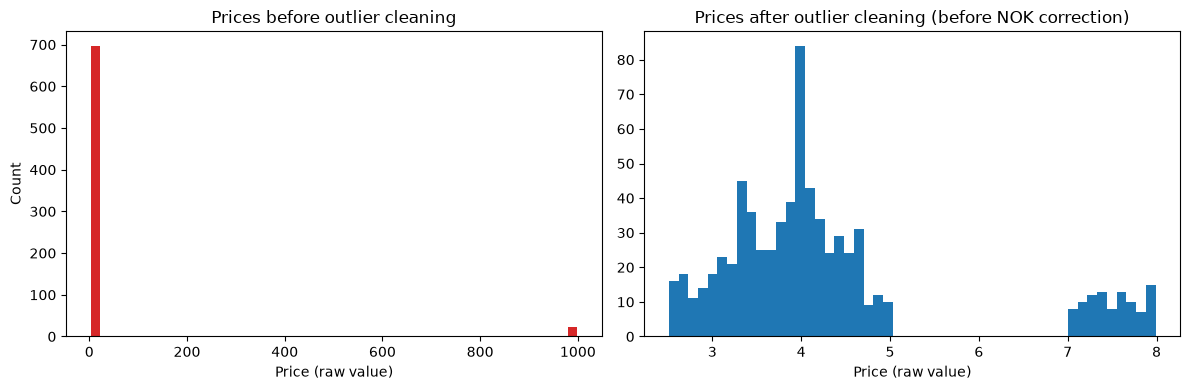

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(results["raw_prices"], bins=50, color="tab:red")
axes[0].set_title("Prices before outlier cleaning")
axes[0].set_xlabel("Price (raw value)")
axes[0].set_ylabel("Count")

axes[1].hist(results["cleaned_prices"], bins=50, color="tab:blue")
axes[1].set_title("Prices after outlier cleaning (before NOK correction)")
axes[1].set_xlabel("Price (raw value)")

plt.tight_layout()
plt.show()

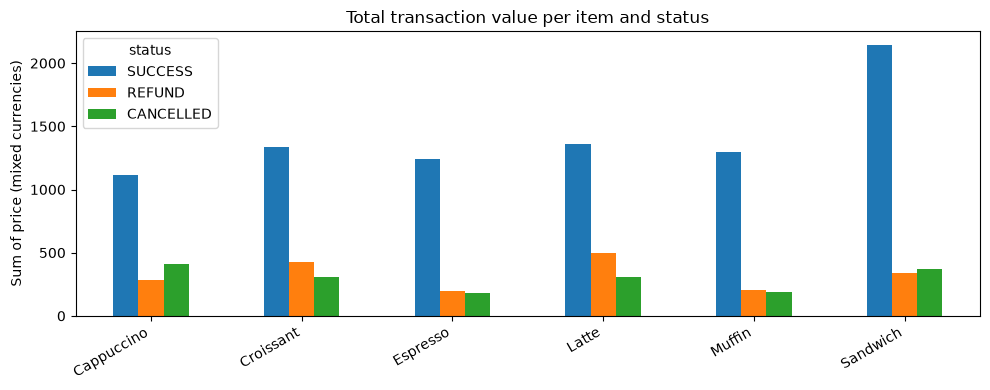

In [21]:
results["pivot"].plot(kind="bar", figsize=(10, 4))
plt.title("Total transaction value per item and status")
plt.ylabel("Sum of price (mixed currencies)")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

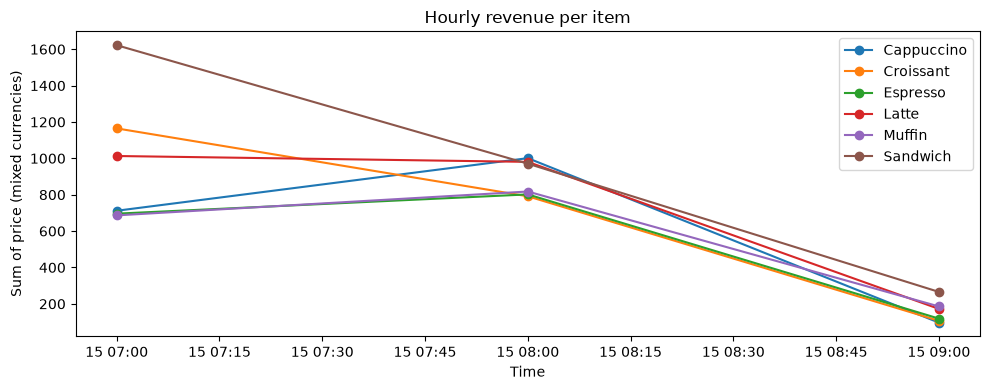

In [22]:
plt.figure(figsize=(10, 4))
for item in results["pivot"].index:
    item_revenue = results["hourly"][item]
    plt.plot(item_revenue.index, item_revenue.values, marker="o", label=item)

plt.title("Hourly revenue per item")
plt.ylabel("Sum of price (mixed currencies)")
plt.xlabel("Time")
plt.legend()
plt.tight_layout()
plt.show()

## Discussion

**Encoding detection.** Trying UTF-8 first and falling back to Latin-1 works because UTF-8 is strict
while Latin-1 accepts every byte. A file containing only ASCII characters is valid in both encodings
and is reported as UTF-8, which is harmless since both decode it to the same text. This is exactly
what happens with the provided generator: every item name is plain ASCII, so the files written as
ISO-8859-1 are byte-for-byte identical to UTF-8 files, and all of them are reported as UTF-8. No
method can tell the two apart in that case, and the decoded text is still correct. The reader
switches to Latin-1 as soon as a file contains a non-ASCII character such as `é`. A limitation is
that the method only distinguishes these two encodings; a file in, for example, UTF-16 would be
decoded incorrectly as Latin-1 without raising an error.

**Regular expressions.** Anchoring the pattern to the full line and restricting `status` to three
values makes the parser strict: it is better to skip a corrupted line than to load wrong data.
The non-greedy item group handles multi-word and accented item names.

**Recursion.** Both recursive functions work on any depth. The config search does not assume a
fixed schema, so it still works if the company adds new nesting levels (for example buildings
inside regions).

**Active registers.** Register ids are not unique across stores: every store folder contains
`POS_01`, `POS_02` and `POS_03`. The config only marks `POS_04` as inactive, and no log files exist
for it, so the filter keeps all transactions in our data. In a real system the filter should use
the combination of store and register id, for example by taking the store name from the folder path.

**Outlier cleaning.** The 3σ rule assumes that outliers are rare. With many glitches the mean and
standard deviation are themselves pulled towards the outliers, and some glitches may slip through.
A more robust alternative would be a median-based rule (median absolute deviation). We replace
rather than delete outliers, as required, so no transactions are lost from counts and ratios, but
the replaced prices are estimates, not real values.

**Currency.** After correction NOK prices are on the right scale, but the reports still sum EUR,
NOK and USD together because the assignment does not ask for conversion. These totals are therefore
not a real revenue figure. A natural extension is to convert all prices to one currency using
exchange rates, or to add `currency` as an extra grouping level.

**Revenue definition.** The hourly report and pivot table sum all transactions as specified. The
pivot table shows the split by status, so true revenue (SUCCESS minus REFUND) can be read from it.

## Reproducibility

- Virtual environment packages: see `requirements.txt`
- Commit log: generated with
  `https://github.com/Didrikwang/Campus_coffee_shop/blob/main/requirements.txt`


## Ai summary

Tool and context
We used Claude (Anthropic) as a tutor and reviewer while writing the code ourselves: to get hints on how to start each task, have concepts explained, and have our finished functions checked.
•	Tool: Claude, in the Claude app
•	Material we shared: the assignment notebook, the lecture slides, our own code function by function, the data generator and our discussion
Questions we asked
The questions below are the ones we actually asked, in order, translated from Norwegian and shortened. Several of them were our own code pasted in for review.
Tasks 1 and 2
1.	We are going to write this code ourselves. Can you help us understand what to do on some of the points?
2.	We are struggling with how to write the regex parser in Task 1.2.
3.	Can you check our regex pattern?
4.	After the pattern, do we define a separate parse function?
5.	Can you check our parse_log_text function?
6.	Should we add an example text below the code? Can you check our example?
7.	How should we start find_log_files? Can you check the finished function?
8.	In Task 2.2, how do we move from one node to the next in the nested config?
9.	What should the if statement check, and why?
10.	Can you check find_active_register_ids and load_store_config?
Tasks 3 and 4
11.	Can you recap NumPy arrays and which expressions matter most for Task 3?
12.	Can you check remove_price_outliers?
13.	What format will the DataFrame have after Task 4.1? Can you check our function?
14.	Can you check our functions for hourly revenue, the pivot table and refund ratios?
15.	Should the type hint for 4.4 just be pd.DataFrame -> pd.DataFrame?
Task 5, discussion and hand-in
16.	Should we first define a correction factor, NOK = 10.0?
17.	Can you check save_hourly_revenue_json?
18.	How do we save the output files and pass the results on from run_pipeline?
19.	Can you check the data generator and the pipeline run? Are the observations a problem?
20.	Is our discussion good enough?

Claude explained concepts, gave hints and reviewed our code; most of the functions, the test cells and the discussion are our own. The code Claude suggested is listed below.
What Claude did
•	Gave an overview of how to approach each task, with hints and skeletons rather than complete solutions.
•	Explained the regex piece by piece and suggested a pattern and parse loop for Task 1.2. We adapted it with line anchors (^...$) and \s+ instead of single spaces.
•	Explained concepts we were unsure of: treating nested JSON as a tree for recursion, isinstance, NumPy boolean masks, and the shape of a DataFrame with a datetime index.
•	Suggested the one-line groupby().resample().sum() in Task 4.2, the code for saving the output files and returning the results in Task 5, and a before/after histogram of the prices.
•	Reviewed our functions and pointed out a KeyError when a status column is missing, a misused "base case" comment, the 1D requirement in Task 3.1, and that the 3σ rule cannot detect a single outlier in small samples.
•	Pointed out observations in the generated data: all item names are ASCII, so every file is reported as UTF-8; register ids are not unique across stores; and there is no random seed.
•	Reviewed our discussion and suggested additional points: the order of outlier cleaning and currency correction, global versus per-item median, and how sales count is defined.
•	Wrote a first draft of this summary based on the chat, which we checked and edited.
What we did and checked ourselves
•	Wrote the functions ourselves from the hints: file reader, file search, active registers and config loader, outlier cleaning, refund ratio, DataFrame builder, pivot table, refund ratios per item, JSON export, and steps 1 to 6 of the pipeline.
•	Wrote our own test cells, including a negative test (a line with status UNKNOWN) and an item name with spaces and a non-ASCII character (Café au Lait).
•	Chose our own solutions where we preferred them: a nested {item: {timestamp: revenue}} structure for the JSON report, pivot_table with count instead of crosstab, and a separate config loader.
•	Wrote the discussion ourselves and decided which of the suggested additions to include.
•	Ran the full pipeline on the generated data and checked the output files.